# LSMO/STO (001) XRD scan
Reads the `.ras` file, extracts header info and the intensity data, and plots it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

fname = "1.XRD_LSMO_Rocking_Curve.ras"   # change path if needed

## 1. Parse the .ras file

In [2]:
def read_ras(path):
    header, data = {}, []
    in_data = False
    with open(path, "r", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if line.startswith("*RAS_INT_START"):
                in_data = True
                continue
            if line.startswith("*RAS_INT_END"):
                in_data = False
                continue
            if in_data:
                parts = line.split()
                if len(parts) >= 2:
                    data.append([float(p) for p in parts[:3]])
            elif line.startswith("*") and " " in line:
                key, val = line[1:].split(" ", 1)
                header[key] = val.strip().strip('"')
    df = pd.DataFrame(data, columns=["angle", "intensity", "atten"][:len(data[0])])
    return header, df

header, df = read_ras(fname)
print(df.shape)
df.head()

(3001, 3)


,angle,intensity,atten
0,20.00,5.9199,1.0
1,20.01,7.9653,1.0
2,20.02,3.9639,1.0
3,20.03,12.9111,1.0
4,20.04,11.8941,1.0


In [3]:
keys = ["MEAS_SCAN_AXIS_X", "MEAS_SCAN_START", "MEAS_SCAN_STOP", "MEAS_SCAN_STEP",
        "MEAS_SCAN_SPEED", "MEAS_SCAN_SPEED_UNIT", "MEAS_COND_XG_VOLTAGE",
        "MEAS_COND_XG_CURRENT", "HW_XG_WAVE_LENGTH_ALPHA1", "MEAS_DATA_COUNT"]
for k in keys:
    print(f"{k:28s}: {header.get(k)}")

MEAS_SCAN_AXIS_X            : TwoThetaOmega
MEAS_SCAN_START             : 20.0000
MEAS_SCAN_STOP              : 50.0000
MEAS_SCAN_STEP              : 0.0100
MEAS_SCAN_SPEED             : 1.5000
MEAS_SCAN_SPEED_UNIT        : deg/min
MEAS_COND_XG_VOLTAGE        : 45
MEAS_COND_XG_CURRENT        : 100
HW_XG_WAVE_LENGTH_ALPHA1    : 1.540593
MEAS_DATA_COUNT             : 3001


## 2. Plot

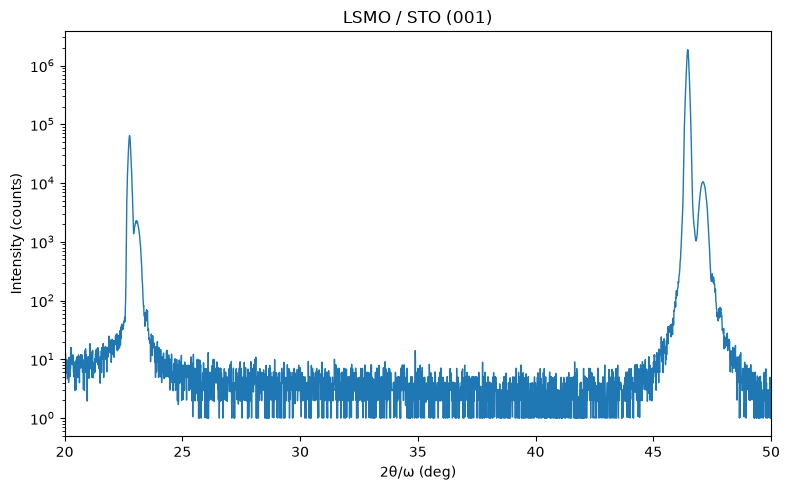

In [4]:
x, y = df["angle"].values, df["intensity"].values
xlabel = "2θ/ω (deg)" if "TwoTheta" in header.get("MEAS_SCAN_AXIS_X", "") else "ω (deg)"

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(x, np.clip(y, 1, None), lw=1, color="C0")
ax.set_xlabel(xlabel)
ax.set_ylabel("Intensity (counts)")
ax.set_title("LSMO / STO (001)")
ax.set_xlim(x.min(), x.max())
plt.tight_layout()
# plt.savefig("lsmo_xrd.png", dpi=300)
plt.show()

## 3. Peak positions and d-spacings

In [5]:
lam = float(header.get("HW_XG_WAVE_LENGTH_ALPHA1", 1.540593))   # Å

# smooth slightly to avoid picking noise
ys = pd.Series(y).rolling(5, center=True, min_periods=1).mean().values
idx, _ = find_peaks(ys, prominence=0.0005*ys.max(), distance=20)

rows = []
for i in idx:
    # refine with parabolic fit on top 5 points
    sl = slice(max(i-2, 0), i+3)
    p = np.polyfit(x[sl], y[sl], 2)
    pos = -p[1] / (2*p[0]) if p[0] < 0 else x[i]
    theta = np.radians(pos / 2)
    rows.append({"2theta (deg)": round(pos, 4), "counts": round(y[i]),
                 "d (Å)": round(lam / (2*np.sin(theta)), 4)})
peaks = pd.DataFrame(rows)
peaks

,2theta (deg),counts,d (Å)
0,22.7592,64247,3.9040
1,46.4651,1856217,1.9528
2,47.1100,10316,1.9275


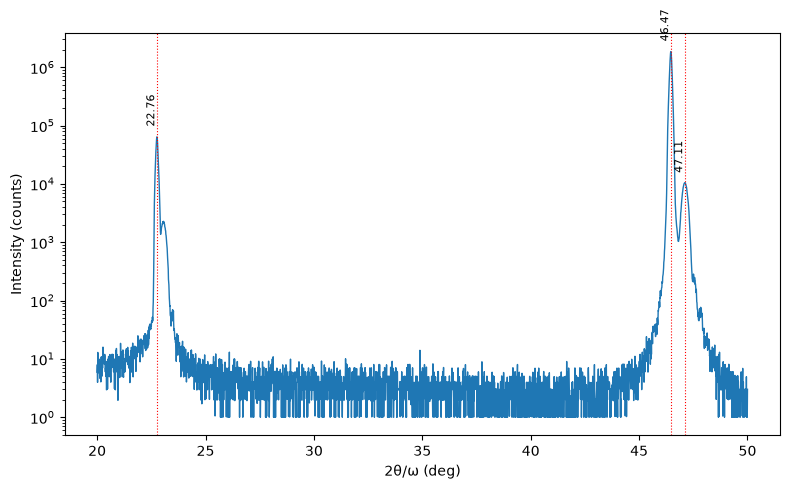

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(x, np.clip(y, 1, None), lw=1)
for _, r in peaks.iterrows():
    ax.axvline(r["2theta (deg)"], color="r", ls=":", lw=0.8)
    ax.text(r["2theta (deg)"], r["counts"]*1.5, f'{r["2theta (deg)"]:.2f}', rotation=90,
            ha="right", va="bottom", fontsize=8)
ax.set_xlabel(xlabel); ax.set_ylabel("Intensity (counts)")
plt.savefig('LSMO_XRD.png', dpi=300, bbox_inches='tight')
plt.tight_layout(); plt.show()

## 4. Zoom on the (002) region (substrate + film)
For a (001) film on STO, the film (002) peak appears as a separate peak/shoulder next to the STO (002). From it, the out-of-plane lattice parameter is c = 2·d₀₀₂.

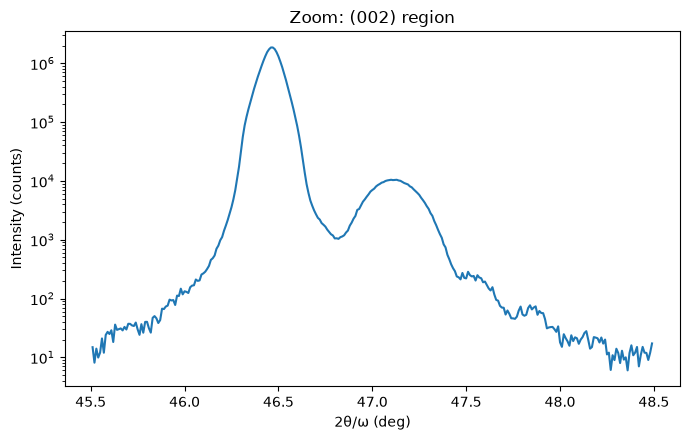

In [7]:
m = (x > 45.5) & (x < 48.5)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(x[m], np.clip(y[m], 1, None))
ax.set_xlabel(xlabel); ax.set_ylabel("Intensity (counts)")
ax.set_title("Zoom: (002) region")
plt.tight_layout(); plt.show()

## 5. Out-of-plane lattice parameter (pseudo-Voigt fit of the (002) peaks)
Bragg's law: c = 2 d(002) = λ / sin θ

,Peak,2theta (deg),err (deg),FWHM (deg),d002 (A),c = 2*d002 (A)
0,STO (002),46.4639,0.0004,0.108,1.9528,3.9056
1,LSMO (002),47.1123,0.0004,0.289,1.9274,3.8549


Out-of-plane lattice parameter of LSMO film: c = 3.8549 A
STO substrate check: a = 3.9056 A (literature 3.905 A)


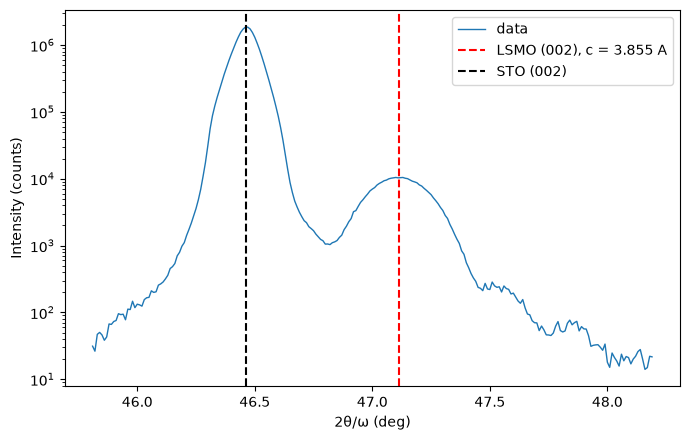

In [10]:
from scipy.optimize import curve_fit

def pseudo_voigt(x, A, x0, w, eta, b):
    g = np.exp(-4*np.log(2)*((x - x0)/w)**2)
    l = 1/(1 + 4*((x - x0)/w)**2)
    return A*(eta*l + (1 - eta)*g) + b

def fit_peak(lo, hi, x0, A):
    m = (x > lo) & (x < hi)
    p, cov = curve_fit(pseudo_voigt, x[m], y[m], p0=[A, x0, 0.1, 0.5, 5],
                       bounds=([0, lo, 0.01, 0, 0], [1e8, hi, 2, 1, 1e4]))
    return p, np.sqrt(np.diag(cov))

results = []
for name, lo, hi, x0, A in [("STO (002)", 46.3, 46.7, 46.465, 1.85e6),
                            ("LSMO (002)", 46.85, 47.45, 47.11, 1e4)]:
    p, e = fit_peak(lo, hi, x0, A)
    d002 = lam / (2*np.sin(np.radians(p[1]/2)))
    results.append({"Peak": name, "2theta (deg)": round(p[1], 4),
                    "err (deg)": round(e[1], 4), "FWHM (deg)": round(p[2], 3),
                    "d002 (A)": round(d002, 4), "c = 2*d002 (A)": round(2*d002, 4)})
res = pd.DataFrame(results)
display(res)

c_film = res.loc[res.Peak == "LSMO (002)", "c = 2*d002 (A)"].iloc[0]
a_sto  = res.loc[res.Peak == "STO (002)",  "c = 2*d002 (A)"].iloc[0]
print(f"Out-of-plane lattice parameter of LSMO film: c = {c_film:.4f} A")
print(f"STO substrate check: a = {a_sto:.4f} A (literature 3.905 A)")

fig, ax = plt.subplots(figsize=(7, 4.5))
m = (x > 45.8) & (x < 48.2)
ax.semilogy(x[m], np.clip(y[m], 1, None), lw=1, label="data")
ax.axvline(res.iloc[1]["2theta (deg)"], color="r", ls="--", label=f"LSMO (002), c = {c_film:.3f} A")
ax.axvline(res.iloc[0]["2theta (deg)"], color="k", ls="--", label="STO (002)")
ax.set_xlabel(xlabel); ax.set_ylabel("Intensity (counts)"); ax.legend()
plt.savefig('LSMO_XRD2.png', dpi=300, bbox_inches='tight')
plt.tight_layout(); plt.show()